In [1]:
import matplotlib.pyplot as plt
import matplotlib
import numpy
import os
import logging, sys
import math
import os.path

from radioimaging.util import util
from radioimaging.evaluation import evaluation
from radioimaging.visibility import residual
from radioimaging.visibility import weights

matplotlib.rcParams['figure.figsize'] = [6, 5]

cmap = "turbo"

breakdowns = [
    "read",
    "grid",
    "degrid",
    "deconvolve",
    "other"
]

breakdowns_parallel = [
    "read",
    "grid",
    "degrid",
    "deconvolve",
    "wait",
    "other"
]

def total_timings(timings, breakdowns):
    total = []
    
    for i, breakdown in enumerate(breakdowns):
        curr_timing = 0

        for timing in timings:
            curr_timing += timing[i]

        total.append(curr_timing)
        
    return total

pcols = ["black", "firebrick", "darkgreen", "royalblue", "darkviolet", "mediumvioletred", "darkturquoise"]

In [2]:
dataset_path = "../data8/HLTau/HLTau_B6cont.calib.noauto.ms"
results_root = "../results/multi_partition_bda_results/HLTau"

num_mc = 5

num_partitions = [1, 4, 6, 8, 10]
split_alphas = [1, 0.2673539390178276, 0.17901225043051766, 0.1434331756113436, 0.12090516086108125]

npix = 512
start_chan = 0
end_chan = 3
spw = [0, 1, 2, 3]
cellsize = 4.2613845905338666e-08
weighting = "uniform"
robustness = 0

compute_residuals = False
compute_jacknifed_residual = False
calculate_pvals = False
override_files = False

In [3]:
pl1_times_sep = []
pl1_times = []
pl1_residuals = []
pl1_pnorms = []
pl1_times_bymc = []

pmsc_times_sep = []
pmsc_times = []
pmsc_residuals = []
pmsc_pnorms = []
pmsc_times_bymc = []

vis_counts = []

for npart in num_partitions:
    l1path = results_root + "/10/l1/mc_timings" if npart == 1 else results_root + "/" + str(npart) + "/pl1/mc_timings"
    mscpath = results_root + "/10/msc/mc_timings" if npart == 1 else results_root + "/" + str(npart) + "/pmsc/mc_timings"
    
    pl1_times_sep.append(util.read_csv(l1path))
    pmsc_times_sep.append(util.read_csv(mscpath))
    
    pl1_times.append([])
    pl1_residuals.append([])
    pl1_pnorms.append([])
    pl1_times_bymc.append([])

    pmsc_times.append([])
    pmsc_residuals.append([])
    pmsc_pnorms.append([])
    pmsc_times_bymc.append([])

In [4]:
#compute reference residual obtained using jackknife resampling
weight_grid = model = None

if compute_residuals:
    weight_grid, _, _ = weights.compute_weights_griddata_from_ms(dataset_path, start_chan, end_chan, spw, npix, cellsize, bda=False)
    psf, model, _, _ = residual.compute_psf_by_channel(dataset_path, start_chan, end_chan, spw, npix, cellsize, weighting, robustness, weight_grid, bda=False)

if compute_jacknifed_residual:
    if weight_grid is None:
        weight_grid, _, _ = weights.compute_weights_griddata_from_ms(dataset_path, start_chan, end_chan, spw, npix, cellsize, bda=False)
        psf, model, _, _ = residual.compute_psf_by_channel(dataset_path, start_chan, end_chan, spw, npix, cellsize, weighting, robustness, weight_grid, bda=False)
        
    jk_resid = evaluation.compute_jackknifed_residual_bychannel(model, dataset_path, npix, cellsize, weighting, robustness, weight_grid, \
                                                                start_chan, end_chan, spw, bda=False)
    util.tofits(jk_resid.pixels.data, results_root + "/jacknifed_resid.fits")

jackknifed = util.fromfits(results_root + "/jacknifed_resid.fits")

In [5]:
#read and compute residuals if requested
if compute_residuals:
    file_exists = os.path.isfile(results_root + "/fullresid_0.fits")
    if override_files or not file_exists:
        curr_resid, _ = residual.compute_residual_from_ms(model, dataset_path, start_chan, end_chan, spw, npix, \
                                                        cellsize, weighting, robustness, weight_grid=weight_grid, bda=False)
        util.tofits(curr_resid.pixels.data[0,0,:,:], results_root + "/fullresid_0.fits")

first_resid = util.fromfits(results_root + "/fullresid_0.fits")

for j, npart in enumerate(num_partitions):
    time_acc_l1 = float(pl1_times_sep[j][0])
    time_acc_msc = float(pmsc_times_sep[j][0])
    
    pl1_residuals[j].append(first_resid)
    pmsc_residuals[j].append(first_resid)
    pl1_times[j].append(time_acc_l1)
    pmsc_times[j].append(time_acc_msc)
    pl1_times_bymc[j].append(time_acc_l1)
    pmsc_times_bymc[j].append(time_acc_msc)

    curr_recon_l1 = None
    curr_recon_msc = None

    for i in range(0, num_mc):
        curr_deconv_l1 = util.fromfits(results_root + "/10/l1/deconvolved_" + str(i) + ".fits") if npart == 1 else \
            util.fromfits(results_root + "/" + str(npart) + "/pl1/recon_combined_" + str(i) + ".fits")
        curr_deconv_msc = util.fromfits(results_root + "/10/msc/deconvolved_" + str(i) + ".fits") if npart == 1 else \
            util.fromfits(results_root + "/" + str(npart) + "/pmsc/recon_combined_" + str(i) + ".fits")

        #we already have the reconstructed images for the parallel methods so no need to add
        if curr_recon_l1 is None or npart > 1:
            curr_recon_l1 = curr_deconv_l1
            curr_recon_msc = curr_deconv_msc
        else:
            curr_recon_l1 += curr_deconv_l1
            curr_recon_msc += curr_deconv_msc
    
        l1path = results_root + "/10/l1/fullresid_" + str(i+1) + ".fits" if npart == 1 else \
                results_root + "/" + str(npart) + "/pl1/fullresid_" + str(i) + ".fits"

        mscpath = results_root + "/10/msc/fullresid_" + str(i+1) + ".fits" if npart == 1 else \
                results_root + "/" + str(npart) + "/pmsc/fullresid_" + str(i) + ".fits"
        
        if compute_residuals:
            file_exists = os.path.isfile(l1path)
            if override_files or not file_exists:
                model.pixels.data[0, 0, :, :] = curr_recon_l1
                curr_resid, _ = residual.compute_residual_from_ms(model, dataset_path, start_chan, end_chan, spw, npix, \
                                                                cellsize, weighting, robustness, weight_grid=weight_grid, bda=False)
                util.tofits(curr_resid.pixels.data[0,0,:,:], l1path)

            file_exists = os.path.isfile(mscpath)
            if override_files or not file_exists:
                model.pixels.data[0, 0, :, :] = curr_recon_msc
                curr_resid, _ = residual.compute_residual_from_ms(model, dataset_path, start_chan, end_chan, spw, npix, \
                                                                cellsize, weighting, robustness, weight_grid=weight_grid, bda=False)
                util.tofits(curr_resid.pixels.data[0,0,:,:], mscpath)
        
        time_acc_l1 += float(pl1_times_sep[j][i+1])
        time_acc_msc += float(pmsc_times_sep[j][i+1])

        curr_resid_l1 = util.fromfits(l1path)
        curr_resid_msc = util.fromfits(mscpath)
        
        pl1_residuals[j].append(curr_resid_l1)
        pmsc_residuals[j].append(curr_resid_msc)
        pl1_times[j].append(time_acc_l1)
        pmsc_times[j].append(time_acc_msc)
        pl1_times_bymc[j].append(float(pl1_times_sep[j][i+1]))
        pmsc_times_bymc[j].append(float(pmsc_times_sep[j][i+1]))

In [6]:
#compute wasserstein distance if requested and take the l2 norms
center = npix//2
for j, npart in enumerate(num_partitions):
    for i in range(0, num_mc+1):
        l1path = results_root + "/10/l1/pvals_" + str(i) + ".fits" if npart == 1 else \
            results_root + "/" + str(npart) + "/pl1/pvals_" + str(i) + ".fits"
        mscpath = results_root + "/10/msc/pvals_" + str(i) + ".fits" if npart == 1 else \
            results_root + "/" + str(npart) + "/pmsc/pvals_" + str(i) + ".fits"
        
        if calculate_pvals:
            file_exists = os.path.isfile(l1path)
            if override_files or not file_exists:
                curr_resid_l1 = pl1_residuals[j][i]
                pvals_l1, _ = evaluation.t_test_image(curr_resid_l1, jackknifed, 5)
                util.tofits(pvals_l1, l1path)
            
            file_exists = os.path.isfile(mscpath)
            if override_files or not file_exists:
                curr_resid_msc = pmsc_residuals[j][i]
                pvals_msc, _ = evaluation.t_test_image(curr_resid_msc, jackknifed, 5)
                util.tofits(pvals_msc, mscpath)

        pvals_l1 = util.fromfits(l1path)#[center-250:center+250, center-250:center+250]
        pvals_msc = util.fromfits(mscpath)

        #util.plotNImages([pvals_msc], [str(i) + " " + str(numpy.linalg.norm(pvals_msc))], cmap=cmap)

        pl1_pnorms[j].append(numpy.linalg.norm(pvals_l1))
        pmsc_pnorms[j].append(numpy.linalg.norm(pvals_msc))

In [7]:
num_partitions = [4, 6, 8, 10]

pl1_breakdown_data = []
pmsc_breakdown_data = []
vis_counts = []

for i in num_partitions:
    curr_pl1_breakdown = []
    curr_pmsc_breakdown = []

    curr_vis_counts = []
    for j in range(i):
        curr_pl1_breakdown.append(util.read_csv(results_root + "/" + str(i) + "/pl1/mc_timings_breakdown_" + str(j), separate_rows=True))
        curr_pmsc_breakdown.append(util.read_csv(results_root + "/" + str(i) + "/pmsc/mc_timings_breakdown_" + str(j), separate_rows=True))
        curr_vis_counts.append(int(curr_pl1_breakdown[-1][0][0]))

    vis_counts.append(max(curr_vis_counts))
    
    pl1_breakdown_data.append(curr_pl1_breakdown)
    pmsc_breakdown_data.append(curr_pmsc_breakdown)
    
seriall1_breakdown_data = util.read_csv(results_root + "/10/l1/mc_timings_breakdown", separate_rows=True)
serialmsc_breakdown_data = util.read_csv(results_root + "/10/msc/mc_timings_breakdown", separate_rows=True)

vis_counts = [int(seriall1_breakdown_data[0][0])] + vis_counts

dirty = util.fromfits(results_root + "/10/l1/residual_0.fits")
#util.plotNImages([dirty], [""], cmap="turbo", hide_ticks=True)

In [8]:
l1_breakdown_data = []
msc_breakdown_data = []

full_msc_breakdown = []
full_l1_breakdown = []

In [9]:
for i, lst in enumerate(seriall1_breakdown_data):
    seriall1_breakdown_data[i] = list(map(float, lst))
    
for i, lst in enumerate(serialmsc_breakdown_data):
    serialmsc_breakdown_data[i] = list(map(float, lst))

serial_l1_timings_bymc = []
serial_msc_timings_bymc = []

serial_l1_timings_bymc.append([seriall1_breakdown_data[1][0], 0, 0, 0, sum(seriall1_breakdown_data[1][1:])])
serial_l1_timings_bymc.append([seriall1_breakdown_data[2][0], seriall1_breakdown_data[2][3], 0, 0, sum(seriall1_breakdown_data[2][1:3]) + seriall1_breakdown_data[2][4]])

serial_msc_timings_bymc.append([serialmsc_breakdown_data[1][0], 0, 0, 0, sum(serialmsc_breakdown_data[1][1:])])
serial_msc_timings_bymc.append([serialmsc_breakdown_data[2][0], serialmsc_breakdown_data[2][3], 0, 0, sum(serialmsc_breakdown_data[2][1:3]) + serialmsc_breakdown_data[2][4]])

for i, curr_mc_timings in enumerate(seriall1_breakdown_data[3:]):
    other_timings = sum(curr_mc_timings[1:4]) + curr_mc_timings[5] + curr_mc_timings[7]
    serial_l1_timings_bymc.append([curr_mc_timings[0], curr_mc_timings[6], curr_mc_timings[4], curr_mc_timings[8], other_timings])

for i, curr_mc_timings in enumerate(serialmsc_breakdown_data[3:]):
    other_timings = sum(curr_mc_timings[1:4]) + curr_mc_timings[5] + curr_mc_timings[7]
    serial_msc_timings_bymc.append([curr_mc_timings[0], curr_mc_timings[6], curr_mc_timings[4], curr_mc_timings[8], other_timings])

l1_breakdown_data.append(total_timings(serial_l1_timings_bymc, breakdowns))
msc_breakdown_data.append(total_timings(serial_msc_timings_bymc, breakdowns))

full_l1_breakdown.append(serial_l1_timings_bymc)
full_msc_breakdown.append(serial_msc_timings_bymc)

In [10]:
for i, partition_config in enumerate(num_partitions):
    for node in range(partition_config):
        curr_pl1_breakdown = pl1_breakdown_data[i][node]

        for j, lst in enumerate(curr_pl1_breakdown):
            curr_pl1_breakdown[j] = list(map(float, lst))

        curr_pmsc_breakdown = pmsc_breakdown_data[i][node]

        for j, lst in enumerate(curr_pmsc_breakdown):
            curr_pmsc_breakdown[j] = list(map(float, lst))
        
        pl1_timings_bymc = []
        pmsc_timings_bymc = []

        pl1_timings_bymc.append([curr_pl1_breakdown[1][0], 0, 0, 0, 0, sum(curr_pl1_breakdown[1][1:])])
        pl1_timings_bymc.append([curr_pl1_breakdown[2][0], curr_pl1_breakdown[2][3], 0, 0, 0, sum(curr_pl1_breakdown[2][1:2]) + curr_pl1_breakdown[2][4]])
        
        pmsc_timings_bymc.append([curr_pmsc_breakdown[1][0], 0, 0, 0, 0, sum(curr_pmsc_breakdown[1][1:])])
        pmsc_timings_bymc.append([curr_pmsc_breakdown[2][0], curr_pmsc_breakdown[2][3], 0, 0, 0, sum(curr_pmsc_breakdown[2][1:2]) + curr_pmsc_breakdown[2][4]])

        for j, curr_mc_timings in enumerate(curr_pl1_breakdown[4:]):
            other_timings = sum(curr_mc_timings[2:5]) + curr_mc_timings[6] + curr_mc_timings[8]
            pl1_timings_bymc.append([curr_mc_timings[1], curr_mc_timings[7], curr_mc_timings[5], curr_mc_timings[9], \
                            curr_mc_timings[10], other_timings])

        for j, curr_mc_timings in enumerate(curr_pmsc_breakdown[5:]):
            other_timings = sum(curr_mc_timings[1:4]) + curr_mc_timings[5] + curr_mc_timings[7]
            pmsc_timings_bymc.append([curr_mc_timings[0], curr_mc_timings[6], curr_mc_timings[4], curr_mc_timings[8], \
                            curr_mc_timings[9] + curr_mc_timings[10], other_timings])
            
        l1_breakdown_data.append(total_timings(pl1_timings_bymc, breakdowns_parallel))
        msc_breakdown_data.append(total_timings(pmsc_timings_bymc, breakdowns_parallel))

        full_l1_breakdown.append(pl1_timings_bymc)
        full_msc_breakdown.append(pmsc_timings_bymc)

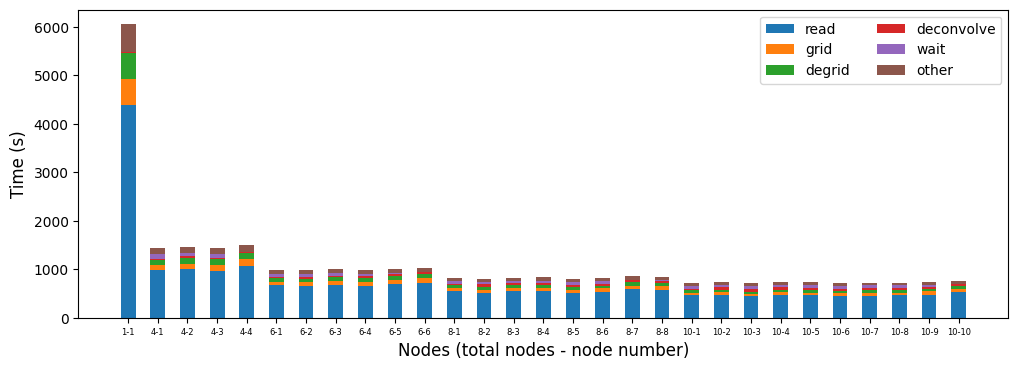

In [11]:
matplotlib.rcParams['figure.figsize'] = [12, 4]
width = 0.5

labels=["1-1"]
labels += ["4-1", "4-2", "4-3", "4-4"]
labels += ["6-1", "6-2", "6-3", "6-4", "6-5", "6-6"]
labels += ["8-1", "8-2", "8-3", "8-4", "8-5", "8-6", "8-7", "8-8"]
labels += ["10-1", "10-2", "10-3", "10-4", "10-5", "10-6", "10-7", "10-8", "10-9", "10-10"]

mask = numpy.array([True, \
                    True, True, True, True, \
                    True, True, True, True, True, True, \
                    True, True, True, True, True, True, True, True, \
                    True, True, True, True, True, True, True, True, True, True])

fig, axes = plt.subplots(1, 1)

bottom = numpy.zeros(len(labels))

for i, curr_breakdown in enumerate(breakdowns_parallel):
    curr_timings = None
    if i == 4:
        curr_timings = [0]
    elif i > 4:
        curr_timings = [msc_breakdown_data[0][i - 1]]
    else:
        curr_timings = [msc_breakdown_data[0][i]]

    for pbreakdown in msc_breakdown_data[1:]:
        curr_timings.append(pbreakdown[i])
        
    p = axes.bar(numpy.array(labels)[mask], numpy.array(curr_timings)[mask], width, label=curr_breakdown, bottom=bottom[mask])
    bottom += curr_timings

#axes.set_title('L1 deconvolution (Sgr A)', fontsize=14)
axes.legend(loc="upper right", fontsize=10, ncol=2)
axes.set_ylabel('Time (s)', fontsize=12)
axes.set_xlabel('Nodes (total nodes - node number)', fontsize=12)
axes.xaxis.set_tick_params(labelsize=6)
#axes.set_ylim(bottom=4000)
    
# bottom = numpy.zeros(len(labels))

# for i, curr_breakdown in enumerate(breakdowns_parallel):
#     curr_timings = None
#     if i == 4:
#         curr_timings = [0]
#     elif i > 4:
#         curr_timings = [msc_breakdown_data[0][i - 1]]
#     else:
#         curr_timings = [msc_breakdown_data[0][i]]

#     for pbreakdown in msc_breakdown_data[1:]:
#         curr_timings.append(pbreakdown[i])
        
#     p = axes[1].bar(numpy.array(labels)[mask], numpy.array(curr_timings)[mask], width, label=curr_breakdown, bottom=bottom[mask])
#     bottom += curr_timings

# axes[1].set_title('MS-Clean deconvolution (Sgr B2)', fontsize=14)
# axes[1].legend(loc="upper right", fontsize=10, ncol=2)
# axes[1].set_ylabel('Time (s)', fontsize=12)
# axes[1].xaxis.set_tick_params(labelsize=6)

plt.savefig("../figures/l1breakdownhltau.pdf", pad_inches=0.0, bbox_inches='tight')

[[4384.34109044075, 1006.1309962272644, 678.877203742663, 547.0046062171459, 466.4276516914368], [545.348062992096, 121.26122862100601, 83.17622832457225, 67.87369805574417, 57.57537450790405], [530.6302468776703, 113.74480086565018, 77.61017207304637, 63.09148535132408, 53.44252851009369], [26.5818829536438, 31.946124374866486, 35.59407206376394, 40.39090219140053, 43.52802450656891], [0.0, 57.41015738248825, 39.72590172290802, 36.00125828385353, 48.82209994792938], [567.3318529129028, 128.69940781593323, 87.74061063925426, 70.04821056127548, 58.79228587150574]]


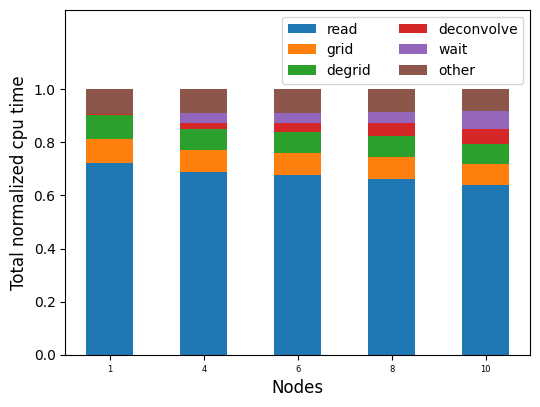

In [12]:
matplotlib.rcParams['figure.figsize'] = [6, 5]
nodes = [1, 4, 6, 8, 10]
all_timings = []
all_timings_total = [0] * len(nodes)
max_timings = []

for i, curr_breakdown in enumerate(breakdowns_parallel):
    curr_timings = None
    if i == 4:
        curr_timings = [0]
    elif i > 4:
        curr_timings = [msc_breakdown_data[0][i - 1]]
    else:
        curr_timings = [msc_breakdown_data[0][i]]

    for pbreakdown in msc_breakdown_data[1:]:
        curr_timings.append(pbreakdown[i])

    curr_timings_aggregated = []
    curr_breakdown_max = []
    
    curr_idx = 0
    for i, n in enumerate(nodes):
        curr_timing = 0
        max_timing = -1
        for j in range(n):
            curr_timing += curr_timings[curr_idx+j]
            max_timing = max(max_timing, curr_timings[curr_idx+j])

        curr_breakdown_max.append(curr_timing/n)
        
        curr_timings_aggregated.append(curr_timing)
        all_timings_total[i] += curr_timing
        curr_idx += n

    all_timings.append(curr_timings_aggregated)
    max_timings.append(curr_breakdown_max)

print(max_timings)

for i, breakdown_group in enumerate(all_timings):
    for j, timing_node in enumerate(breakdown_group):
        all_timings[i][j] = all_timings[i][j] / all_timings_total[j]

width = 0.5
bottom = numpy.zeros(len(nodes))
labels=["1", "4", "6", "8", "10"]

fig, axes = plt.subplots(1, 1)
for i, curr_breakdown in enumerate(breakdowns_parallel):
    curr_timings = all_timings[i]
    #print(curr_timings)
    p = axes.bar(labels, curr_timings, width, label=curr_breakdown, bottom=bottom)
    bottom += curr_timings

x = numpy.arange(len(nodes))

axes.legend(loc="upper right", fontsize=10, ncol=2)
axes.set_ylabel('Total normalized cpu time', fontsize=12)
axes.set_xlabel('Nodes', fontsize=12)
axes.set_xticks(x)
axes.set_xticklabels(numpy.array(labels))
axes.xaxis.set_tick_params(labelsize=6)
fig.subplots_adjust(top=0.8)
axes.margins(y=0.3)
axes.set_yticks(numpy.arange(0, 1.01, 0.2))
plt.savefig("../figures/normalizedmscbreakdownsgra2.pdf", pad_inches=0.0, bbox_inches='tight')

In [13]:
for item in max_timings:
    line = ""
    for i, n in enumerate(nodes):
        denom = item[i] if item[i] > 0 else 1e-2
        times = str(round(item[0] / denom, 1))
        line += str(int(item[i])) + "s (" + times + ") & "
    print(line)

4384s (1.0) & 1006s (4.4) & 678s (6.5) & 547s (8.0) & 466s (9.4) & 
545s (1.0) & 121s (4.5) & 83s (6.6) & 67s (8.0) & 57s (9.5) & 
530s (1.0) & 113s (4.7) & 77s (6.8) & 63s (8.4) & 53s (9.9) & 
26s (1.0) & 31s (0.8) & 35s (0.7) & 40s (0.7) & 43s (0.6) & 
0s (0.0) & 57s (0.0) & 39s (0.0) & 36s (0.0) & 48s (0.0) & 
567s (1.0) & 128s (4.4) & 87s (6.5) & 70s (8.1) & 58s (9.6) & 


[[3843.298426389694, 1032.0637267231941, 693.5561581055323, 558.4051473736763, 464.0607131719589], [464.4259753227234, 121.14491683244705, 83.9011522134145, 67.47552385926247, 57.75252394676208], [439.8270859718323, 113.60301065444946, 78.09327101707458, 62.85459777712822, 53.79345855712891], [106.64086842536926, 124.67372471094131, 133.55498560269675, 145.48167926073074, 156.02069256305694], [0.0, 0.07323986291885376, 0.12477755546569824, 0.11910340189933777, 0.15527145862579345], [537.0666630268097, 128.57762241363525, 87.81408846378326, 70.16685763001442, 59.69536559581756]]


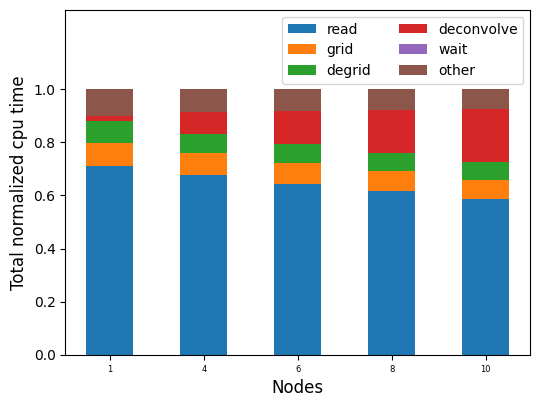

In [14]:
matplotlib.rcParams['figure.figsize'] = [6, 5]
nodes = [1, 4, 6, 8, 10]
all_timings = []
all_timings_total = [0] * len(nodes)
max_timings = []

for i, curr_breakdown in enumerate(breakdowns_parallel):
    curr_timings = None
    if i == 4:
        curr_timings = [0]
    elif i > 4:
        curr_timings = [l1_breakdown_data[0][i - 1]]
    else:
        curr_timings = [l1_breakdown_data[0][i]]

    for pbreakdown in l1_breakdown_data[1:]:
        curr_timings.append(pbreakdown[i])

    curr_timings_aggregated = []
    curr_breakdown_max = []
    
    curr_idx = 0
    for i, n in enumerate(nodes):
        curr_timing = 0
        max_timing = -1
        for j in range(n):
            curr_timing += curr_timings[curr_idx+j]
            max_timing = max(max_timing, curr_timings[curr_idx+j])

        curr_breakdown_max.append(curr_timing/n)
        
        curr_timings_aggregated.append(curr_timing)
        all_timings_total[i] += curr_timing
        curr_idx += n

    all_timings.append(curr_timings_aggregated)
    max_timings.append(curr_breakdown_max)

print(max_timings)

for i, breakdown_group in enumerate(all_timings):
    for j, timing_node in enumerate(breakdown_group):
        all_timings[i][j] = all_timings[i][j] / all_timings_total[j]

width = 0.5
bottom = numpy.zeros(len(nodes))
labels=["1", "4", "6", "8", "10"]

fig, axes = plt.subplots(1, 1)
for i, curr_breakdown in enumerate(breakdowns_parallel):
    curr_timings = all_timings[i]
    #print(curr_timings)
    p = axes.bar(labels, curr_timings, width, label=curr_breakdown, bottom=bottom)
    bottom += curr_timings

x = numpy.arange(len(nodes))

axes.legend(loc="upper right", fontsize=10, ncol=2)
axes.set_ylabel('Total normalized cpu time', fontsize=12)
axes.set_xlabel('Nodes', fontsize=12)
axes.set_xticks(x)
axes.set_xticklabels(numpy.array(labels))
axes.xaxis.set_tick_params(labelsize=6)
fig.subplots_adjust(top=0.8)
axes.margins(y=0.3)
axes.set_yticks(numpy.arange(0, 1.01, 0.2))
plt.savefig("../figures/normalizedl1breakdownsgra2.pdf", pad_inches=0.0, bbox_inches='tight')

In [15]:
for item in max_timings:
    line = ""
    for i, n in enumerate(nodes):
        denom = item[i] if item[i] > 0 else 1e-2
        times = str(round(item[0] / denom, 1))
        line += str(int(item[i])) + "s (" + times + ") & "
    print(line)

3843s (1.0) & 1032s (3.7) & 693s (5.5) & 558s (6.9) & 464s (8.3) & 
464s (1.0) & 121s (3.8) & 83s (5.5) & 67s (6.9) & 57s (8.0) & 
439s (1.0) & 113s (3.9) & 78s (5.6) & 62s (7.0) & 53s (8.2) & 
106s (1.0) & 124s (0.9) & 133s (0.8) & 145s (0.7) & 156s (0.7) & 
0s (0.0) & 0s (0.0) & 0s (0.0) & 0s (0.0) & 0s (0.0) & 
537s (1.0) & 128s (4.2) & 87s (6.1) & 70s (7.7) & 59s (9.0) & 


In [16]:
pcols = ["black", "firebrick", "darkgreen", "royalblue", "darkviolet", "mediumvioletred", "darkturquoise"]
err = [2] * len(pl1_pnorms[0])
matplotlib.rcParams['figure.figsize'] = [6, 5]
num_partitions = [1, 4, 6, 8, 10]

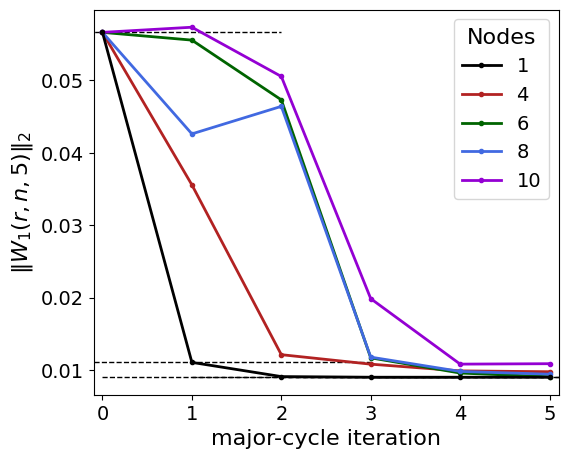

In [17]:
c = plt.errorbar(range(6), pmsc_pnorms[0], xerr=err, c=pcols[0], label="1", lw=2, marker='o', markersize=3, elinewidth=1)
c[2][0].set_linestyle('--')
handles = [c]

for i, partition_config in enumerate(num_partitions):
    if i == 0:
        continue
    h, = plt.plot(range(6), pmsc_pnorms[i], c=pcols[i], label=str(partition_config), lw=2, marker='o', markersize=3)
    handles.append(h)

plt.legend(handles = handles, title="Nodes", loc="upper right", fontsize=14, title_fontsize=16)
plt.xlabel("major-cycle iteration", fontsize=16)
plt.ylabel("$\|W_1(r, n, 5)\|_2$", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(-0.1, 5.1)

plt.savefig("../figures/hltaumsc_accuracy_bymc.pdf", pad_inches=0.0, bbox_inches='tight')

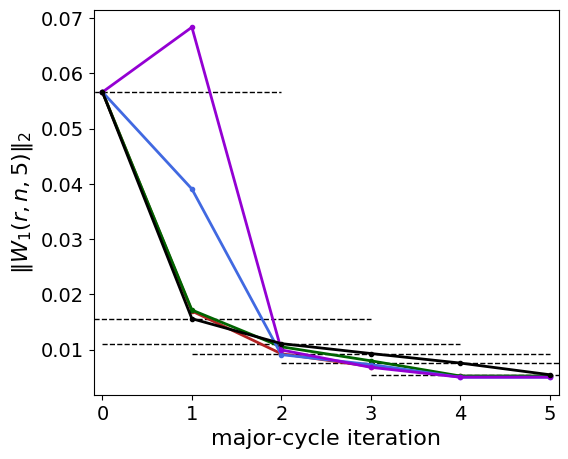

In [18]:
c = plt.errorbar(range(6), pl1_pnorms[0], xerr=err, c=pcols[0], label="1", lw=2, marker='o', markersize=3, elinewidth=1)
c[2][0].set_linestyle('--')
handles = [c]

for i, partition_config in enumerate(num_partitions):
    if i == 0:
        continue
    h, = plt.plot(range(6), pl1_pnorms[i], c=pcols[i], label=str(partition_config), lw=2, marker='o', markersize=3)
    handles.append(h)

#plt.legend(handles = handles, title="Nodes", loc="upper right", fontsize=14, title_fontsize=16)
plt.xlabel("major-cycle iteration", fontsize=16)
plt.ylabel("$\|W_1(r, n, 5)\|_2$", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(-0.1, 5.1)

plt.savefig("../figures/hltaul1_accuracy_bymc.pdf", pad_inches=0.0, bbox_inches='tight')

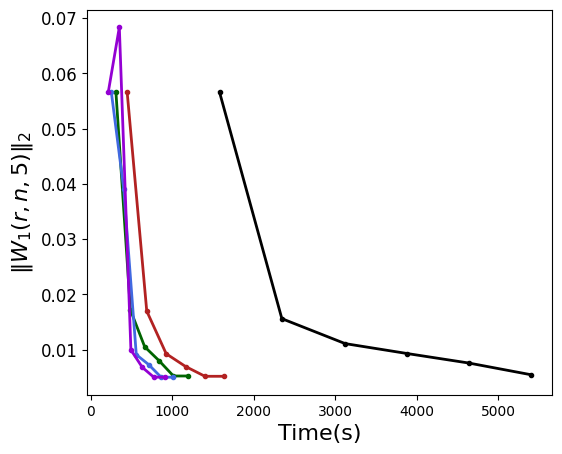

In [19]:
c = plt.errorbar(pl1_times[0], pl1_pnorms[0], xerr=err, c=pcols[0], label="1", lw=2, marker='o', markersize=3, elinewidth=1)
c[2][0].set_linestyle('--')
handles = [c]

for i, partition_config in enumerate(num_partitions):
    if i == 0:
        continue
    h, = plt.plot(pl1_times[i], pl1_pnorms[i], c=pcols[i], label=str(partition_config), lw=2, marker='o', markersize=3)
    handles.append(h)

#plt.legend(handles = handles, title="Nodes", loc="upper right", fontsize=14, title_fontsize=16)
plt.xlabel("Time(s)", fontsize=16)
plt.ylabel("$\|W_1(r, n, 5)\|_2$", fontsize=16)
plt.yticks(fontsize=12)

plt.savefig("../figures/hltaul1_accuracy_bytime.pdf", pad_inches=0.0, bbox_inches='tight')

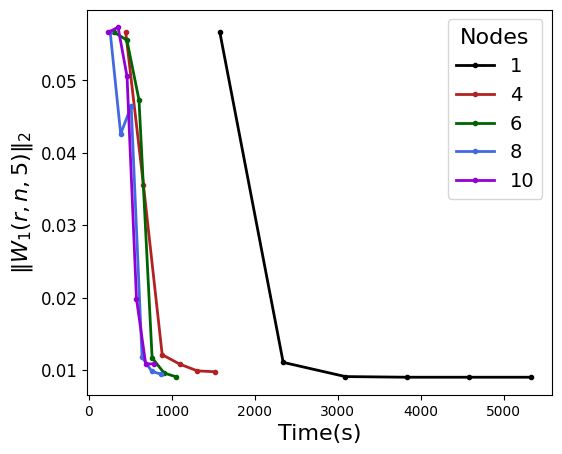

In [20]:
c = plt.errorbar(pmsc_times[0], pmsc_pnorms[0], xerr=err, c=pcols[0], label="1", lw=2, marker='o', markersize=3, elinewidth=1)
c[2][0].set_linestyle('--')
handles = [c]

for i, partition_config in enumerate(num_partitions):
    if i == 0:
        continue
    h, = plt.plot(pmsc_times[i], pmsc_pnorms[i], c=pcols[i], label=str(partition_config), lw=2, marker='o', markersize=3)
    handles.append(h)

plt.legend(handles = handles, title="Nodes", loc="upper right", fontsize=14, title_fontsize=16)
plt.xlabel("Time(s)", fontsize=16)
plt.ylabel("$\|W_1(r, n, 5)\|_2$", fontsize=16)
plt.yticks(fontsize=12)

plt.savefig("../figures/hltaumsc_accuracy_bytime.pdf", pad_inches=0.0, bbox_inches='tight')

In [21]:
num_partitions = [4, 6, 8, 10]

pl1_breakdown_data = []
pmsc_breakdown_data = []
vis_counts = []

for i in num_partitions:
    curr_pl1_breakdown = []
    curr_pmsc_breakdown = []

    curr_vis_counts = []
    for j in range(i):
        curr_pl1_breakdown.append(util.read_csv(results_root + "/" + str(i) + "/pl1/mc_timings_breakdown_" + str(j), separate_rows=True))
        curr_pmsc_breakdown.append(util.read_csv(results_root + "/" + str(i) + "/pmsc/mc_timings_breakdown_" + str(j), separate_rows=True))
        curr_vis_counts.append(int(curr_pl1_breakdown[-1][0][0]))

    vis_counts.append(max(curr_vis_counts))
    
    pl1_breakdown_data.append(curr_pl1_breakdown)
    pmsc_breakdown_data.append(curr_pmsc_breakdown)
    
seriall1_breakdown_data = util.read_csv(results_root + "/10/l1/mc_timings_breakdown", separate_rows=True)
serialmsc_breakdown_data = util.read_csv(results_root + "/10/msc/mc_timings_breakdown", separate_rows=True)

vis_counts = [int(seriall1_breakdown_data[0][0])] + vis_counts

dirty = util.fromfits(results_root + "/10/l1/residual_0.fits")
#util.plotNImages([dirty], [""], cmap="turbo", hide_ticks=True)

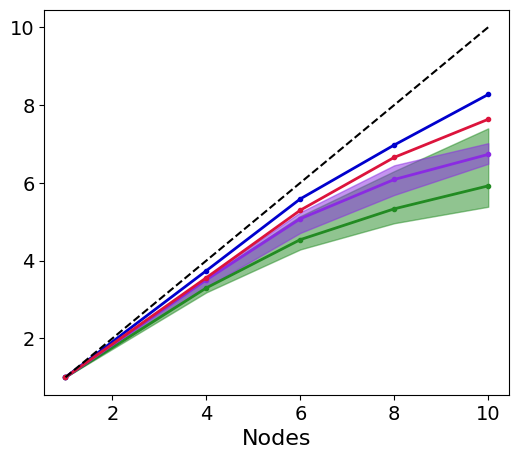

In [24]:
mcl1_times = [[1] for x in pl1_times_bymc[0][0:num_mc + 1]]
mcmsc_times = [[1] for x in pmsc_times_bymc[0][0:num_mc + 1]]

totl1_times = [1]
totmsc_times = [1]

l1max = [1]
l1min = [1]
mscmax = [1]
mscmin = [1]

nnodes = [1] + num_partitions

cmapl1 = matplotlib.colormaps['viridis']  
colorsl1 = cmapl1(numpy.linspace(0, 0.8, num_mc + 1))

for i, partition_config in enumerate(num_partitions):
    for mc in range(num_mc + 1):
        mcl1_times[mc].append(pl1_times_bymc[0][mc] / pl1_times_bymc[i+1][mc])
        mcmsc_times[mc].append(pmsc_times_bymc[0][mc] / pmsc_times_bymc[i+1][mc])

    totl1_times.append(pl1_times[0][-1] / pl1_times[i+1][-1])
    totmsc_times.append(pmsc_times[0][-1] / pmsc_times[i+1][-1])

l1transpose = numpy.transpose(numpy.array(mcl1_times))
l1max = numpy.max(l1transpose, axis=1)
l1min = numpy.min(l1transpose, axis=1)
msctranspose = numpy.transpose(numpy.array(mcmsc_times))
mscmax = numpy.max(msctranspose, axis=1)
mscmin = numpy.min(msctranspose, axis=1)

for mc in range(num_mc + 1):
    lbl = str(mc) if mc > 0 else str(mc) + " (psf & weights)"
    #plt.plot(nnodes, mcl1_times[mc], c=colorsl1[mc], alpha=0.6, label=lbl, lw=2, marker='o', markersize=4)

plt.plot(nnodes, totl1_times, c="forestgreen", label=r"L1 speedup" "\n" "(relative)", lw=2, marker='o', markersize=3)
plt.fill_between(nnodes, l1min, l1max, edgecolor="forestgreen", facecolor="forestgreen", alpha=0.5)

cmapmsc = matplotlib.colormaps['inferno']  
colorsmsc = cmapmsc(numpy.linspace(0, 0.8, num_mc + 1))

for mc in range(num_mc + 1):
    lbl = str(mc) if mc > 0 else str(mc) + " (psf & weights)"
    #plt.plot(nnodes, mcmsc_times[mc], c=colorsmsc[mc], alpha=1, label=lbl, lw=2, marker='o', markersize=4)

plt.plot(nnodes, totmsc_times, c="blueviolet", label=r"ms-clean speedup" "\n" "(relative)", lw=2, marker='o', markersize=3)
plt.fill_between(nnodes, mscmin, mscmax, edgecolor="blueviolet", facecolor="blueviolet", alpha=0.5)

curr_alphas = 1 / numpy.array(split_alphas)
viscount_ratios = vis_counts[0] / numpy.array(vis_counts)

plt.plot(nnodes, curr_alphas, c="mediumblue", label=r"$1/\alpha$", lw=2, marker='o', markersize=3)
plt.plot(nnodes, viscount_ratios, c="crimson", label=r"$n_{\text{V}}/\text{max}(n_{\text{V}_i})$", lw=2, marker='o', markersize=3)

diag = [x + 1 for x in range(10)]

plt.plot(diag, diag, "--", c="black")

#plt.legend(loc="upper left", frameon=False, fontsize=15)
#plt.ylabel("Wall-time speedup", fontsize=16)
plt.xlabel("Nodes", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.savefig("../figures/hltau_scaling.pdf", pad_inches=0.0, bbox_inches='tight')